# # Lab 1 — Intro to Behavioral TV Data
# Name: Yeremenko Anton | Group: KM-41

## Setup

In [104]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")

# Colab and Kaggle

programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

In [105]:
progvals = programs.values.tolist()
castset = set(); progset = set(); netset = set()
for el in progvals:
    castset.add(el[0])
    progset.add(el[4])
    netset.add(el[1])

dwvals = daily_weights.values.tolist()
houseset = set(); personset = set()
for el in dwvals:
    if el[1] == 'H':
        houseset.add(el[0])
    else:
        personset.add(el[0])

housecount = 0; personcount = 0
currdayhouse = set(); currdayperson = set()
housewgt = 0; personwgt = 0
day = dwvals[0][2]
for el in dwvals:
    if el[2] == day:
        if el[1] == 'H':
            currdayhouse.add(el[0])
            housewgt += el[3]
        else:
            currdayperson.add(el[0])
            personwgt += el[3]
    else:
        day = el[2]
        housecount += len(currdayhouse)
        personcount += len(currdayperson)
        currdayhouse = set()
        currdayperson = set()

## Task 1.1 — Panel and universe

In [106]:
print("Telecasts:", len(castset))
print("Programs:", len(progset))
print("Networks:", len(netset))
print("Households in panel:", len(houseset))
print("Persons in panel:", len(personset))
print("Households in-tab, average day:", int(housecount/31))
print("Persons in-tab, average day:", int(personcount/31))
print("US TV households represented, average day (M):", int(housewgt/31/10000)/100)
print("US persons represented, average day (M):", int(personwgt/31/10000)/100)

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3752
Persons in-tab, average day: 8968
US TV households represented, average day (M): 125.76
US persons represented, average day (M): 317.27


## Task 1.2 — Average audience by hour of day

In [107]:
# Tuesday 1st
viewvals = viewings.values.tolist()
week = []
weekend = []
for i in range(0,30):
    week.append(0); weekend.append(0)
for el in viewvals:
    start = [el[5].date().day,el[5].time().hour,el[5].time().minute]
    end = [el[6].date().day,el[6].time().hour,el[6].time().minute]
    end[1] = end[1] + (24 if (end[1] < start[1]) else 0)
    daydelta = start[0] - (1 if start[1] < 6 else 0) - 1
    sessionlen = end[1] * 60 + end[2] - start[1] * 60 - start[2]
    if daydelta%7==4 or daydelta%7==5:
        for i in range(0,end[1]-start[1]+1):
            if i < end[1] - start[1]:
                if i==0:
                    weekend[start[1]+i] += (60 - start[2])/60*el[8]
                else:
                    weekend[start[1]+i] += el[8]
            else:
                weekend[start[1]+i] += end[2]/60*el[8]
    else:
        for i in range(0,end[1]-start[1]+1):
            if i < end[1] - start[1]:
                if i==0:
                    week[start[1]+i] += (60 - start[2])/60*el[8]
                else:
                    week[start[1]+i] += el[8]
            else:
                week[start[1]+i] += end[2]/60*el[8]
for i in range(24,30):
    week[i-24] += week[i]
    weekend[i-24] += weekend[i]
for i in range(0,24):
    week[i] = int(week[i]/31/10000)/100
    weekend[i] = int(weekend[i]/31/10000)/100
week = week[0:24]
weekend = weekend[0:24]

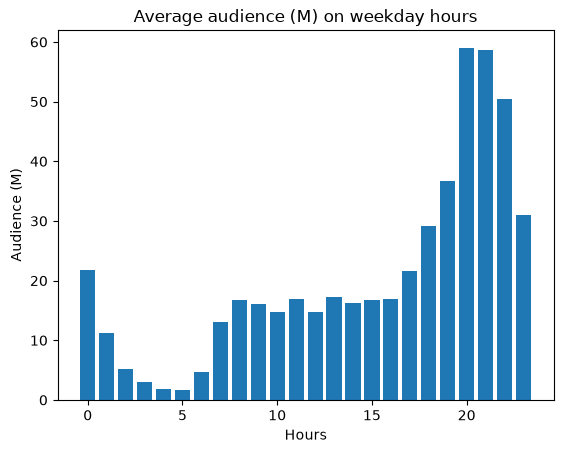

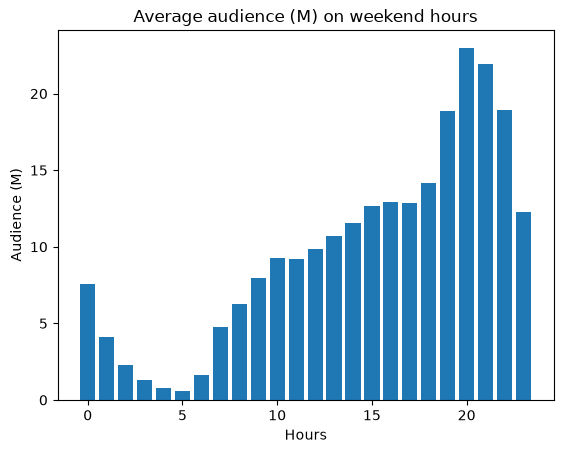

Peak hour, weekdays: 20
Peak hour, weekends: 20


In [108]:
import matplotlib.pyplot as plt

hours = []
for i in range(0,24):
    hours.append(i)

plt.bar(hours,week)
plt.title('Average audience (M) on weekday hours')
plt.xlabel('Hours')
plt.ylabel('Audience (M)')
plt.show()

plt.bar(hours,weekend)
plt.title('Average audience (M) on weekend hours')
plt.xlabel('Hours')
plt.ylabel('Audience (M)')
plt.show()

print("Peak hour, weekdays:", week.index(max(week)))
print("Peak hour, weekends:", weekend.index(max(weekend)))

# **Answer:** how the weekend differs.

## Task 1.3 — Session length

In [109]:
times = []
wgts = []
for el in viewvals:
    time = 0
    if el[6].time().hour < el[5].time().hour:
        time += (el[6].time().hour + 24) * 60 + el[6].time().minute - el[5].time().hour * 60 - el[5].time().minute
    else:
        time += el[6].time().hour * 60 + el[6].time().minute - el[5].time().hour * 60 - el[5].time().minute
    if time not in times:
        times.append(time)
        wgts.append(el[8])
    else:
        wgts[times.index(time)] += el[8]
timewgt = []
totalwgt = 0
wgtedtime = 0
for i in range(0,len(times)):
    timewgt.append([wgts[i],times[i]])
    wgtedtime += times[i] * wgts[i]
    totalwgt += wgts[i]
timewgt = sorted(timewgt)
# len = 310, avg els = id 154 & id 155
mediantime = (timewgt[int((len(timewgt)-1)/2+0.5)][1] + timewgt[int((len(timewgt)-1)/2-0.5)][1]) /2

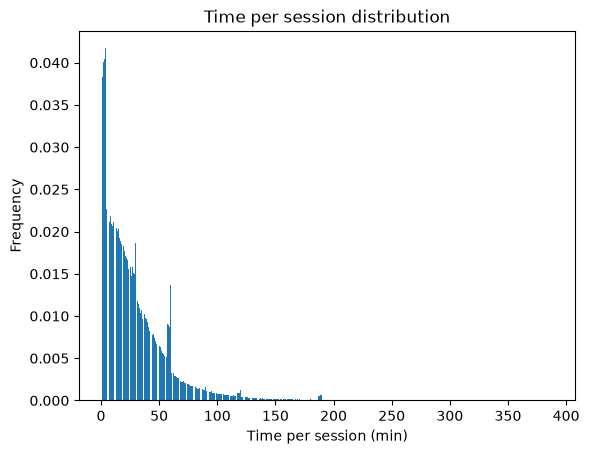

Session length, weighted mean (min): 29
Session length, weighted median (min): 154


In [110]:
timesorted = []
for i in range(0,len(timewgt)):
    timesorted.append([timewgt[i][1],timewgt[i][0]])
timesorted = sorted(timesorted)
times0 = []; wgts0 = []
for i in range(0,len(timesorted)):
    times0.append(timesorted[i][0]); wgts0.append(timesorted[i][1]/totalwgt)

plt.bar(times0,wgts0)
plt.title('Time per session distribution')
plt.xlabel('Time per session (min)')
plt.ylabel('Frequency')
plt.show()

print("Session length, weighted mean (min):", int(wgtedtime/totalwgt))
print("Session length, weighted median (min):", int(mediantime))

# **Answer:** why mean and median differ; which one you would show a client.
I would show the mean, as it shows the average time users spend watching better, compared to median which just picks the middle value of all times based on weights, which doesnt show just how much bigger weights on smaller watch times are.

## Task 2 — Program reach curve

In [111]:
hsumcbs = 0; hsumtotal = 0
psumcbs = 0; psumtotal = 0
audience = 0; tcasts = 0
for el in viewvals:
    if el[2] == 'H':
        if el[4] == "CBS":
            hsumcbs += el[8]
            audience += el[8]
            tcasts += 1
        hsumtotal += el[8]
    else:
        if el[4] == "CBS":
            psumcbs += el[8]
            audience += el[8]
            tcasts += 1
        psumtotal += el[8]

viewattrvals = viewer_attributes.values.tolist()

respid2 = set()
respid34 = set()
respid49 = set()
for el in viewattrvals:
    if el[1] == 302:
        respid2.add(int(el[0]))
    if el[1] >= 318 and el[1] <= 325:
        respid34.add(int(el[0]))
    if el[1] >= 318 and el[1] <= 335:
        respid49.add(int(el[0]))
allwgts = 0
restwgts2 = 0
restwgts34 = 0
restwgts49 = 0
for el in dwvals:
    if el[0] in respid2:
        restwgts2 += el[3]
    if el[0] in respid34:
        restwgts34 += el[3]
    if el[0] in respid49:
        restwgts49 += el[3]
    allwgts += el[3]

In [112]:
table = {
"household rating": [int(hsumcbs/hsumtotal*100)],
"P2+ rating": [int(psumcbs/psumtotal*100)],
"projected audience (M) per telecast": [int(audience/tcasts/10000)/100]}
df = pd.DataFrame(data=table)
print(df)
# ... plot: cumulative reach P2+, A18-34, A18-49
print("Telecasts of the program:", tcasts)
print("Average household rating (%):", int(hsumcbs/hsumtotal*1000)/10)
print("Average P2+ rating (%):", int(psumcbs/psumtotal*1000)/10)
print("Average projected audience (M):", int(audience/10000)/100)
print("Final reach P2+ (%):", int(restwgts2/allwgts*1000)/10)
print("Final reach A18-34 (%):", int(restwgts34/allwgts*1000)/10)
print("Final reach A18-49 (%):", int(restwgts49/allwgts*1000)/10)

   household rating  P2+ rating  projected audience (M) per telecast
0                19          19                                 0.03
Telecasts of the program: 192323
Average household rating (%): 19.2
Average P2+ rating (%): 19.6
Average projected audience (M): 6750.33
Final reach P2+ (%): 3.5
Final reach A18-34 (%): 16.3
Final reach A18-49 (%): 30.2


# **Answer:** reach vs rating; which audience is reached best, and why.
rating shows how likely people are to choose a certain telecast compared to others, while reach shows the distribution of watchers by categories such as age. its probably better to compare by reach, as its harder to guess if youll reach desired outcomes by looking at telecast audience predictions, compared to for example age category predictions.

## Task 3 — Program frequency

In [113]:
def tstoi(ts):
    return ts.date().day*24*60 + ts.time().hour*60 + ts.time().minute
progtimes = []
for el in progvals:
    if el[4] == "The Young and the Restless":
        progtimes.append([tstoi(el[10]),tstoi(el[11])])
progwgt = 0
resps = []
respfreq = []
for el in viewvals:
    if el[4] == "CBS":
        c=0
        for el0 in progtimes:
            if tstoi(el[5]) in range(el0[0],el0[1]) or tstoi(el[6]) in range(el0[0],el0[1]) or el0[0] in range(tstoi(el[5]),tstoi(el[6])):
                c+=1
                break
        if c==1:
            progwgt += el[8]
            if el[1] not in resps:
                resps.append(el[1])
                respfreq.append(1)
            else:
                respfreq[resps.index(el[1])] += 1

In [114]:
forfreq = []
for i in range(0,len(resps)):
    forfreq.append([respfreq[i],resps[i]])
forfreq = sorted(forfreq)
viewers = []; freqs = []
sumfreq = 0; cnt = 0;
for i in range(0,len(forfreq)):
    viewers.append(forfreq[i][1]); freqs.append(forfreq[i][0])
    cnt += 1; sumfreq += forfreq[i][0]
#len freqs = 1881 so med freq id = (1881-1) /2
viewerwgt = []
for i in range(0,len(viewers)):
    viewerwgt.append(0)
for el in viewvals:
    if el[1] in viewers:
        viewerwgt[viewers.index(el[1])] += el[8]
freqset = set(freqs)
totalfreqs = []
for i in range(0,len(freqset)):
    totalfreqs.append(0)
for i in range(0,len(viewerwgt)):
    viewerwgt[i] = int(viewerwgt[i]/10000)/100
    totalfreqs[freqs[i]-1] += viewerwgt[i]

loyalwgt = 0
for i in range(int(0.8*len(forfreq)),len(forfreq)):
    loyalwgt += forfreq[i][0]

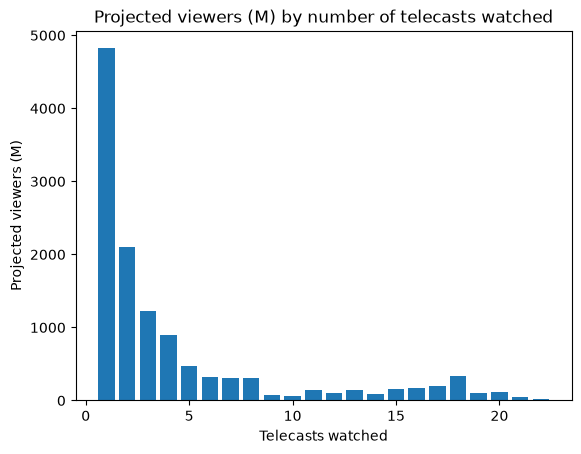

Projected viewers (M): 240.96
Average frequency (weighted): 3
Median frequency (weighted): 2
Share of views from the most loyal viewers: 0.634


In [115]:
plt.bar(list(freqset),totalfreqs)
plt.title("Projected viewers (M) by number of telecasts watched")
plt.xlabel("Telecasts watched")
plt.ylabel("Projected viewers (M)")
plt.show()

print("Projected viewers (M):", int(progwgt/10000)/100)
print("Average frequency (weighted):", int(sumfreq/cnt))
print("Median frequency (weighted):", forfreq[int((len(freqs)-1)/2)][0])
print("Share of views from the most loyal viewers:", int(loyalwgt/sumfreq*1000)/1000)

# **Answer:** is the average frequency a fair summary?
average frequency shows by weights how much people watch, but it doesnt show the overwhelming majority of people staying for 1-2 telecasts, so i doubt theres much to gain from average alone without median (not counting other stats).

## Task 4 — Networks by age and gender

In [116]:
s = set()
for el in viewattrvals:
    s.add(int(el[0]))
ids = list(s)
idtype = []
for i in range(0,len(ids)):
    idtype.append(set())
for el in viewattrvals:
    idtype[ids.index(int(el[0]))].add(int(el[1]))
ids0 = []
idtype0 = []
for i in range(0,len(idtype)):
    agec = 0
    for age in [318,321,325,335,350,355,365]:
        if age in idtype[i]:
            agec += 1
    sexc = 0
    for sex in [201,202]:
        if sex in idtype[i]:
            sexc += 1
    if sexc > 0 and agec > 0:
        type0 = (3 if (202 in idtype[i]) else 0) + (2 if (355 in idtype[i] or 365 in idtype[i]) else (1 if (335 in idtype[i] or 350 in idtype[i]) else 0))
        idtype0.append(type0)
        ids0.append(ids[i])
s = set()
for el in viewvals:
    s.add(el[4])
channels = list(s)
channeltw = []
for i in range(0,len(channels)):
    channeltw.append([0,0,0,0,0,0])
for el in viewvals:
    if el[1] in ids0:
        x = tstoi(el[6]) - tstoi(el[5])
        if x < 0: #no month
            break
        channeltw[channels.index(el[4])][idtype0[ids0.index(el[1])]] += el[8] * x

In [117]:
tws = [[],[],[],[],[],[]]
for i in range(0,len(channeltw)):
    for j in range(0,6):
        tws[j].append([channeltw[i][j],channels[i]])
for i in range(0,6):
    tws[i] = list(reversed(sorted(tws[i])))
tops = [[],[],[],[],[],[]]
for i in range(0,6):
    for j in range(0,5):
        tops[i].append(tws[i][j][1])

sharesch = []
for i in range(0,10):
    netsum = 0
    sum1834 = 0
    for j in range(0,6):
        if j==0 or j==3:
            sum1834 += channeltw[i][j]
        netsum += channeltw[i][j]
    sharesch.append(int(sum1834/netsum*1000)/1000)

In [118]:
table = {"M18-34": tops[0],"M35-54": tops[1],"M55+": tops[2],"W18-34":tops[3],"W35-54":tops[4],"W55+":tops[5]}
df = pd.DataFrame(data=table)
print(df)
for i in range(0,10):
    print(f"{channels[i]} {sharesch[i]}")

print("Youngest network:", channels[sharesch.index(max(sharesch))])
print("Oldest network:", channels[sharesch.index(min(sharesch))])

  M18-34 M35-54 M55+ W18-34 W35-54 W55+
0    FOX    FOX  CBS    FOX    NBC  CBS
1    NBC    NBC  NBC    NBC    FOX  NBC
2    CBS    ABC  FOX    ABC    ABC  ABC
3    ABC    CBS  ABC    CBS    CBS  FOX
4     FX     FX  FNC     FX   HGTV  FNC
BRAVO 0.158
FOOD 0.085
FNC 0.018
CBS 0.054
FX 0.294
NBC 0.079
ABC 0.068
FOX 0.088
HIST 0.049
HGTV 0.061
Youngest network: FX
Oldest network: FNC


# **Answer:** weighted vs raw.
-
# **Bonus answer:** the sales pitch.
i would pitch it as an untapped market brimming with potential since the channel is "underexplored" by young adults